In [2]:
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("muted")

print("Berhasil dimuat!")

Berhasil dimuat!


In [3]:
PROJECT_ROOT = Path.cwd().parent
CLEAN_DATA_PATH = str(PROJECT_ROOT / 'data' / 'processed' / 'dataset_bersih.parquet')

df = pl.read_parquet(CLEAN_DATA_PATH)

In [4]:
print(f"{df.height:,} baris x {df.width} kolom")
display(df.head())

99,671 baris x 15 kolom


id,news_title,news_source,news_author,news_hostname,news_date,news_text,news_tags,news_kabkot,news_intent,news_image,update_date,create_date,news_guid,news_raw_data
str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""1924973""","""Dana Kegiatan Isbat Nikah Baka…","""https://radarutara.disway.id/m…","""Wahyudi""","""disway.id""","""2026-04-27 01:30:00+00:00""","""Dana Kegiatan Isbat Nikah Baka…","""['apbd perubahan 2026', 'diaju…","""Kabupaten Mukomuko""","""{'intent': 'lapor_informasi', …","""Tidak Ada Gambar""","""2026-04-27 03:08:50.074774+00:…",null,"""CBMiswFBVV95cUxOaDhvMVNUZFRlel…","""{'id': None, 'url': 'https://r…"
"""1925951""","""Satu Orang Meninggal dari Insi…","""https://www.ayokaltim.com/satu…","""Iswanto""","""ayokaltim.com""","""2026-04-27 03:19:46+00:00""","""Satu Orang Meninggal dari Insi…","""['Peristiwa di Samarinda;Tabra…","""Kota Samarinda""","""{'intent': 'lapor_informasi', …","""Tidak Ada Gambar""","""2026-04-27 05:26:20.891514+00:…",null,"""CBMimgFBVV95cUxQSkNndGh1VGxOek…","""{'id': None, 'url': 'https://w…"
"""1925952""","""DPRD Bongkar Ketidaksesuaian L…","""https://infosatu.co/dprd-bongk…","""Emmy Haryanti""","""infosatu.co""","""2026-04-27 03:59:29+00:00""","""Samarinda, infosatu.co – Klaim…","""['Abdul rohim;DPRD Samarinda;L…","""Kota Samarinda""","""{'intent': 'lapor_informasi', …","""Tidak Ada Gambar""","""2026-04-27 05:26:20.891632+00:…",null,"""CBMirwFBVV95cUxOMFMxOGNOWlZtT1…","""{'id': None, 'url': 'https://i…"
"""1925953""","""DPRD Dorong Penanganan Banjir …","""https://infosatu.co/dprd-doron…","""Emmy Haryanti""","""infosatu.co""","""2026-04-27 01:43:24+00:00""","""Samarinda, infosatu.co – Dewan…","""['Banjir;Deni Hakim Anwar;DPRD…","""Kota Samarinda""","""{'intent': 'lapor_informasi', …","""Tidak Ada Gambar""","""2026-04-27 05:26:20.891650+00:…",null,"""CBMirwFBVV95cUxPMGdaZU9wVTR0ZG…","""{'id': None, 'url': 'https://i…"
"""1924974""","""Kepung Pasar Karang Nabire, Ma…","""https://papuatengah.tribunnews…","""Calvin Eluis Erari""","""tribunnews.com""","""2026-04-27 02:14:39+00:00""","""Demo di Nabire Kepung Pasar Ka…","""[]""","""Kabupaten Nabire""","""{'intent': 'lapor_informasi', …","""Tidak Ada Gambar""","""2026-04-27 03:09:48.135779+00:…",null,"""CBMi1wFBVV95cUxNbHNySlhzMDFFV1…","""{'id': None, 'url': 'https://p…"


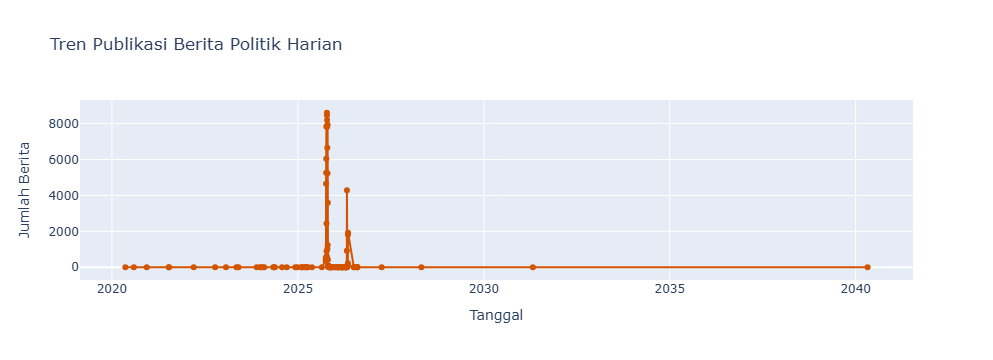

In [9]:
trend_harian_bersih = trend_harian[trend_harian["tanggal"].dt.year >= 2020]

fig1 = px.line(
    trend_harian_bersih, 
    x="tanggal", 
    y="count", 
    title="Tren Publikasi Berita Politik Harian",
    labels={"tanggal": "Tanggal", "count": "Jumlah Berita"},
    markers=True,
    color_discrete_sequence=["#d35400"]
)

fig1.update_traces(hovertemplate='<b>Tanggal:</b> %{x|%d %b %Y}<br><b>Jumlah Berita:</b> %{y:,.0f}<extra></extra>')
fig1.update_layout(hovermode="x unified")
fig1.show()

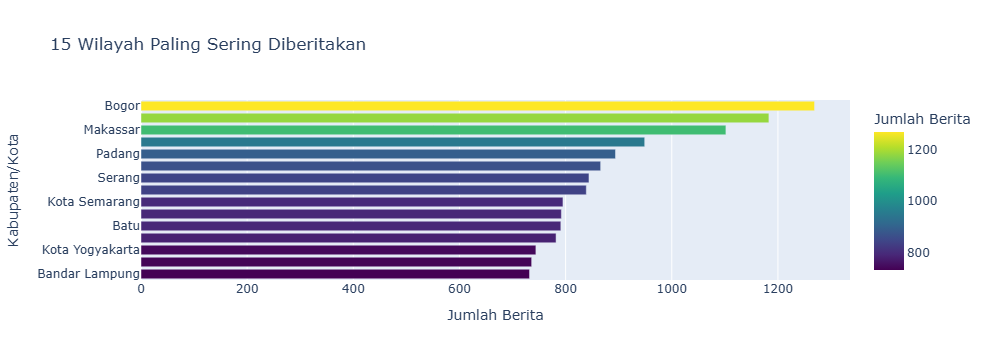

In [10]:
top_kabkot = df.filter(pl.col("news_kabkot").is_not_null())["news_kabkot"].value_counts().sort("count", descending=True).head(15).to_pandas()

fig2 = px.bar(
        top_kabkot,
        x="count",
        y="news_kabkot",
        orientation='h',
        title="15 Wilayah Paling Sering Diberitakan",
        labels={"count": "Jumlah Berita", "news_kabkot": "Kabupaten/Kota"},
        color="count",
        color_continuous_scale="Viridis"
)

fig2.update_layout(yaxis={'categoryorder':'total ascending'})
fig2.show()

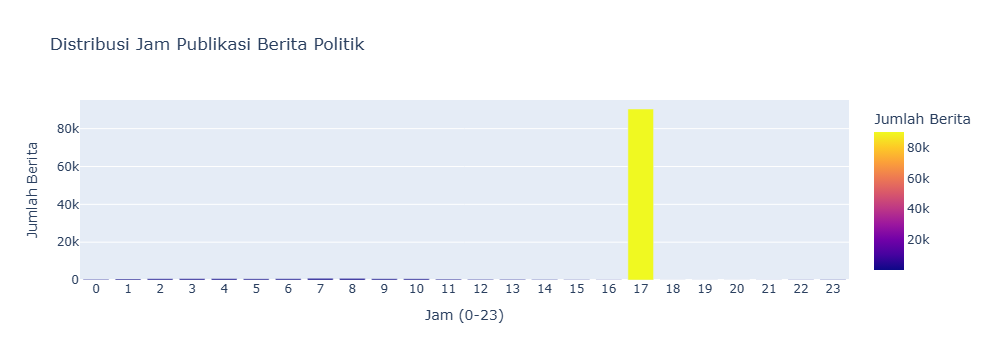

In [11]:
df_jam = df.with_columns(
    pl.col("news_date").str.slice(11, 2).cast(pl.Int32).alias("jam_rilis")
)

# Menghitung frekuensi per jam
dist_jam = df_jam.filter(pl.col("jam_rilis").is_not_null())["jam_rilis"].value_counts().sort("jam_rilis").to_pandas()

# Membuat grafik histogram batang interaktif
fig3 = px.bar(
    dist_jam,
    x="jam_rilis",
    y="count",
    title="Distribusi Jam Publikasi Berita Politik",
    labels={"jam_rilis": "Jam (0-23)", "count": "Jumlah Berita"},
    color="count",
    color_continuous_scale="Plasma"
)

fig3.update_layout(xaxis=dict(tickmode='linear', tick0=0, dtick=1))
fig3.show()

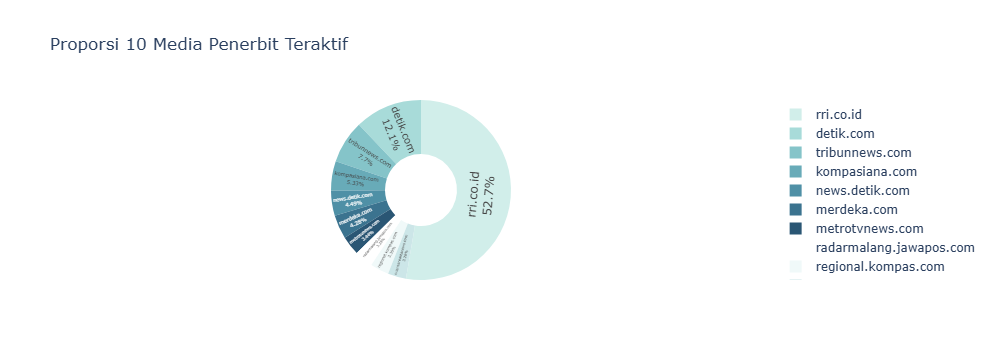

In [12]:
top_media = df["news_hostname"].value_counts().sort("count", descending=True).head(10).to_pandas()

fig4 = px.pie(
    top_media,
    names="news_hostname",
    values="count",
    title="Proporsi 10 Media Penerbit Teraktif",
    hole=0.4, # Membuat lubang di tengah (Donut chart)
    color_discrete_sequence=px.colors.sequential.Teal
)
fig4.update_traces(textposition='inside', textinfo='percent+label')
fig4.show()

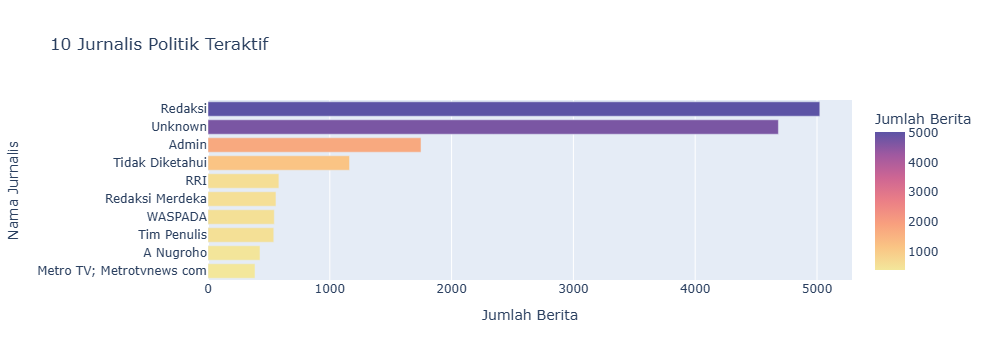

In [13]:
top_authors = df.filter(pl.col("news_author").is_not_null())["news_author"].value_counts().sort("count", descending=True).head(10).to_pandas()

fig5 = px.bar(
    top_authors,
    x="count",
    y="news_author",
    orientation='h',
    title="10 Jurnalis Politik Teraktif",
    labels={"count": "Jumlah Berita", "news_author": "Nama Jurnalis"},
    color="count",
    color_continuous_scale="Sunset"
)
fig5.update_layout(yaxis={'categoryorder':'total ascending'})
fig5.show()

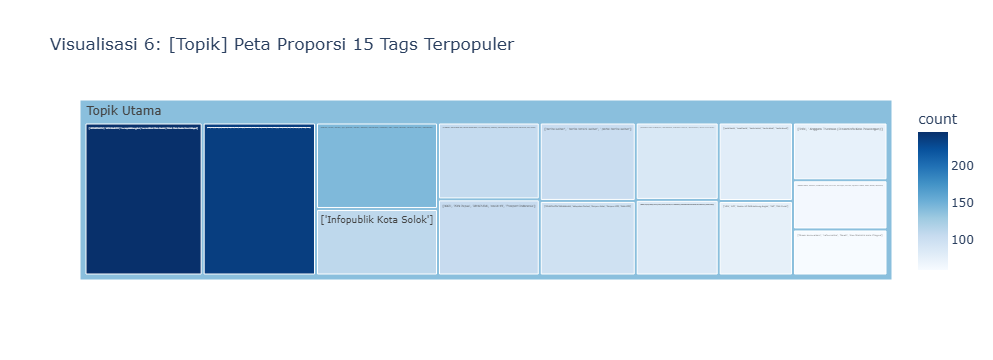

In [15]:
top_tags = df.filter(
    (pl.col("news_tags").is_not_null()) & 
    (pl.col("news_tags") != "[]") &
    (pl.col("news_tags") != '[""]') &
    (pl.col("news_tags") != "['']")
)["news_tags"].value_counts().sort("count", descending=True).head(15).to_pandas()

fig6 = px.treemap(
    top_tags,
    path=[px.Constant("Topik Utama"), "news_tags"],
    values="count",
    title="Visualisasi 6: [Topik] Peta Proporsi 15 Tags Terpopuler",
    color="count",
    color_continuous_scale="Blues"
)
fig6.update_traces(root_color="lightgrey")
fig6.show()